# Wider-Prior Fits on All 26 Relationship Types — Predicted Conditions vs Observed Correlations

New NPE fits of conditions 01–04 (`*_wider`, trained 2026-11-08 on `nn_training_<cond>_wider.csv`) were
conditioned on the EA4 PGS correlations (`observed_correlations_PGS_ea4new.csv`) and the updated EA
phenotypic correlations (`observed_correlations_pheno_021126.csv`). Each condition was then simulated at the
posterior means (`Scripts/run_rc_paper/run_predicted_condition_rc_*.py`, 100 replicates, N = 40,000, compiled
with `compile_predicted_condition.py`), and this notebook compares the simulated relative correlations with
the observed ones.

**What differs from the previous run** (`Analysis_NPE_ea4pheno.ipynb`, same observed data):
- the priors are wider, mostly 0.05–0.95 (founder h² could be 0.56–0.83 before, or 0.63–0.83 in condition 03, and
  can now be 0.51–0.95);
- the fits use all 26 relationship types, PGS and phenotypic (52 correlations), instead of 16;
- conditions 02 and 03 run 15 generations instead of 20;
- in condition 04, `n_gen` = 3 is left out of the fit, which leaves 17,500 training simulations (20,000 in 01–03).

> **Heritability in this notebook.** These predictions came from the simulation engine as it was before the fix
> of 2026-11-08. On that engine the scripts' `vg` is not heritability: the genetic variance is about 1 whatever
> `vg` is, and `vg` only sets the environmental variance 1 − `vg`. Every table and comment below therefore
> reports the **founder (base) heritability, h² = 1/(2 − `vg`)**, converted from the fitted `vg`, in place of `vg`
> itself. Simulations on that engine support the conversion: `vg` = 0.05, 0.35 and 0.80 gave a founder h² of 0.511,
> 0.611 and 0.840, against 0.513, 0.606 and 0.833 from the formula
> (`run_rc_paper_wider/diagnose_02_03/results/exp1_engine_scale.csv`). On that engine h² cannot go below 0.51, so
> the 0.3–0.4 wanted for EA was out of reach in this run, and `s_mat` has no effect.
>
> As a check that these runs used the old engine, simulating condition 02 at its fitted `vg1` of 0.057 on the
> corrected engine (4 replicates, N = 12,000) gives a sibling phenotypic correlation of 0.045, against 0.434 in the
> file used here. The re-run on the corrected engine, where `vg` is the founder heritability, is in
> `Scripts/run_rc_paper_rescaled/`.

**Reading the figures.** For each relationship type, the bars are the simulated PGS correlations (blue) and
phenotypic correlations (teal; error bars: SD across the 100 replicates); the diamond on each bar is the
observed value. All 26 types are sorted by the observed PGS correlation.

**Fit criteria.** Simulated and observed correlations are compared on Fisher's z scale (z = arctanh r), as in
the previous notebook: *RMSE (z)* is the root-mean-square difference and *bias (z)* the mean of simulated −
observed. *Misfit* is the measure of `run_rc_paper_wider/diagnose_02_03/diagnose_02_03.ipynb`: the
root-mean-square over the 52 correlations of (simulated − observed) / √(SE² + 0.01²). About 1 would mean
agreement within sampling error. The tables still split the 26 types into the 16 original and 10 added ones
so they can be compared with the previous run, but all 26 are now fit, so the 10 added types are no longer an
out-of-sample test.

**Results in short.**
- **Condition 02 gains most.** Its phenotypic RMSE (z) falls from 0.119 to 0.053 and its misfit from 5.66 to
  2.61, close to condition 04 (2.51), which remains the best.
- **Condition 03 improves but is still far off.** PGS RMSE 0.099 → 0.088, phenotypic 0.292 → 0.165, misfit
  12.9 → 8.4. All 52 correlations are over-predicted, and 68.5% of its training simulations fit better than
  the simulation at the estimate.
- **Conditions 01 and 04 barely change.** 01 is slightly worse (misfit 4.18 → 4.50 for trait 1); 04 is
  slightly better (2.58 → 2.51).
- **Founder heritability falls to the lowest value this engine allows in 01, 02 and 03.** It goes from 0.56–0.79
  to 0.51–0.52, against a floor of 0.51. Condition 04 is the exception (0.60 → 0.58).
- **No condition reproduces the data.** The misfit is at least 2.5 everywhere, and no training simulation of
  02 or 03 has the observed spouse and sibling phenotypic correlations together.
- **These are not final estimates.** The next step is the re-run on the corrected engine (last section).

Parameter meanings, the simulation model and the NPE are documented in the repository `README.md`.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from pathlib import Path

# ── Paths and observed data ────────────────────────────────────────────────
script_dir = Path(".")
pgs_table = pd.read_csv(script_dir / "observed_correlations_PGS_ea4new.csv").set_index("RelType")
pheno_table = pd.read_csv(script_dir / "observed_correlations_pheno_021126.csv").set_index("RelType")
obs_pgs, obs_pheno = pgs_table["Correlation"], pheno_table["Correlation"]

# the 16 relationship types the earlier fits use, and the 10 that only the wider fits use
old_types = pd.read_csv(script_dir / "observed_correlations_PGS.csv")["RelType"]
ORIGINAL_TYPES = [t for t in old_types if t in obs_pgs.index]
ADDED_TYPES = [t for t in obs_pgs.index if t not in set(old_types)]
ALL_TYPES = list(obs_pgs.index)
print(f"{len(ORIGINAL_TYPES)} original types: {ORIGINAL_TYPES}")
print(f"{len(ADDED_TYPES)} added types: {ADDED_TYPES}")

# this run, and the previous one (same observed data, narrower priors, the 16 original types)
RUNS = {"wider": "wider priors, 26 types (this run)", "ea4pheno": "narrower priors, 16 types"}


def run_dir(fit, run="wider"):
    return script_dir / f"results_npe_unweighted_{fit}{'_wider' if run == 'wider' else ''}"


def predictions_dir(fit, run="wider"):
    return run_dir(fit, run) / ("predictions" if run == "wider" else "predictions_ea4pheno")


def pred_path(fit, run="wider"):
    """Predicted-condition summary file of this run (wider) or of the previous one (ea4pheno)."""
    return predictions_dir(fit, run) / f"summary_statistics_{fit}_{run}.csv"


# condition -> NPE fit(s) giving its parameters, folder of its summary file and compared trait(s);
# fit names are given without the _wider suffix
CONDITIONS = {
    "01DirAM": dict(title="Condition 01 — Direct AM", fits=["01DirAM_AE", "01DirAM_AFE"],
                    summary="01DirAM_AE", traits=[(1, "Trait 1 (AE)"), (2, "Trait 2 (AFE)")]),
    "02AElatentAM": dict(title="Condition 02 — AE latent AM", fits=["02AElatentAM"],
                         summary="02AElatentAM", traits=[(1, "Trait 1 (EA)")]),
    "03EnvLatentAM": dict(title="Condition 03 — Environmental latent AM", fits=["03EnvLatentAM"],
                          summary="03EnvLatentAM", traits=[(1, "Trait 1 (EA)")]),
    "04EAmigration": dict(title="Condition 04 — EA-driven migration", fits=["04EAmigration"],
                          summary="04EAmigration", traits=[(1, "Trait 1 (EA)")]),
}

MEANING = {
    "prop_h2_latent1": "share of trait-1 genetic variance not captured by the PGS",
    "prop_h2_latent2": "share of trait-2 genetic variance not captured by the PGS",
    "vg1": "founder (base) heritability of trait 1, 1/(2 − vg1)",
    "vg2": "founder (base) heritability of trait 2, 1/(2 − vg2)",
    "am11": "spousal correlation on trait 1",
    "am22": "spousal correlation on trait 2",
    "f11": "vertical transmission, trait 1",
    "f22": "vertical transmission, trait 2",
    "re": "environmental correlation between the traits",
    "rg": "genetic correlation between the traits",
    "move_p": "fraction of each sex per island migrating each generation",
    "n_gen": "generations since the random founders (categorical posterior)",
}

# colours as in Analysis_NPE_ea4pheno.ipynb: PGS blue, phenotypic teal, ACCENT for the estimate
BAR_COLORS = {"PGS": "#2a78d6", "Phenotypic": "#199e70"}
ACCENT = "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
TOL = 0.01    # correlation-scale tolerance added to the observed SE in the misfit

# Founder heritability replaces the scripts' vg in every table. On the engine these runs used, the
# genetic variance is about 1 whatever vg is, and vg only sets the environmental variance 1 − vg.
H2_LABEL = {"vg1": "h²1 (founder)", "vg2": "h²2 (founder)"}


def founder_h2(vg):
    return 1 / (2 - vg)


def show(df, precision=4):
    display(df.style.hide(axis="index").format(precision=precision, na_rep="–"))


def simulated_range(fit, run):
    cfg = json.loads((run_dir(fit, run) / "config.json").read_text())
    bounds = dict(zip(cfg["prior_params"], zip(cfg["prior_lower"], cfg["prior_upper"])))
    if cfg.get("count_param"):
        bounds[cfg["count_param"]] = (min(cfg["count_values"]), max(cfg["count_values"]))
    return bounds


def parameter_table(key):
    """Posterior of every estimated parameter (founder h² in place of vg), with its range and the previous value."""
    rows = []
    for fit in CONDITIONS[key]["fits"]:
        new = pd.read_csv(predictions_dir(fit) / "posterior_summary.csv").set_index("parameter")
        prev = pd.read_csv(predictions_dir(fit, "ea4pheno") / "posterior_summary.csv").set_index("parameter")
        draws = pd.read_csv(predictions_dir(fit) / "posterior_samples.csv")
        bounds, prev_bounds = simulated_range(fit, "wider"), simulated_range(fit, "ea4pheno")
        sampling = json.loads((predictions_dir(fit) / "posterior_sampling.json").read_text())
        print(f"{fit}_wider: {sampling['share_of_unconstrained_flow_inside_prior']:.1%} of the unrestricted "
              f"posterior inside the simulated range -> {sampling['sampling_method']} sampling "
              f"({sampling['n_samples']:,} draws)")
        for p, r in new.iterrows():
            scale = founder_h2 if p in H2_LABEL else (lambda v: v)
            lo, hi = scale(np.array(bounds[p]))
            estimate = scale(r["mean"])       # for h²: the value the predicted condition was simulated at
            earlier = scale(prev.loc[p, "mean"]) if p in prev.index else np.nan
            rows.append({"NPE fit": f"{fit}_wider", "parameter": H2_LABEL.get(p, p), "meaning": MEANING[p],
                         "estimate": estimate,
                         "posterior SD": founder_h2(draws[p]).std() if p in H2_LABEL else r["std"],
                         "95% interval": f"{scale(r['ci_lower_2.5']):.3f} – {scale(r['ci_upper_97.5']):.3f}",
                         "simulated range": f"{lo:.2f} – {hi:.2f}",
                         "position in range": f"{100 * (estimate - lo) / (hi - lo):.0f}%",
                         "previous estimate": earlier,
                         "previous range": ("{:.2f} – {:.2f}".format(*scale(np.array(prev_bounds[p])))
                                            if p in prev_bounds else "fixed"),
                         "change": estimate - earlier})
    show(pd.DataFrame(rows))


def load_summary(csv_path):
    """Predicted-condition summary_statistics CSV -> one row per relationship type."""
    df = pd.read_csv(csv_path)
    wide = df.pivot(index="RelationshipPath", columns="Variable",
                    values=["Correlation_Mean", "Correlation_SD"])
    wide.columns = [f"{v}_{c}" for v, c in wide.columns]
    return wide


def z_diff(pred, obs):
    """Simulated − observed correlations on Fisher's z scale (z = arctanh r)."""
    return np.arctanh(pred) - np.arctanh(obs)


def errors(pred, obs, types):
    """RMSE and bias of simulated against observed correlations over `types`, on Fisher's z scale."""
    p, o = pred.reindex(types), obs.reindex(types)
    ok = p.notna() & o.notna()
    diff = z_diff(p[ok], o[ok])
    return {"n": int(ok.sum()), "RMSE (z)": np.sqrt((diff ** 2).mean()), "bias (z)": diff.mean()}


def error_table(frame, trait):
    groups = [(f"{label}, {name}", var, obs, types)
              for label, var, obs in (("PGS", "PGS", obs_pgs), ("phenotypic", "Y", obs_pheno))
              for name, types in (("16 original types", ORIGINAL_TYPES), ("10 added types", ADDED_TYPES),
                                  ("all 26 types", ALL_TYPES))]
    return pd.DataFrame([{"correlations": label,
                          **errors(frame[f"Correlation_Mean_{var}{trait}"], obs, types)}
                         for label, var, obs, types in groups])


def misfit_of(frame, trait):
    """RMS over the 52 correlations of (simulated − observed) / sqrt(SE² + 0.01²), as in diagnose_02_03."""
    parts = [(frame[f"Correlation_Mean_{var}{trait}"].reindex(ALL_TYPES) - table["Correlation"].reindex(ALL_TYPES))
             / np.sqrt(table["SE"].reindex(ALL_TYPES) ** 2 + TOL ** 2)
             for var, table in (("PGS", pgs_table), ("Y", pheno_table))]
    return float(np.sqrt((pd.concat(parts) ** 2).mean()))


def error_box(ax, table, misfit):
    """Box in the top-right corner: RMSE (Fisher z) of the PGS and phenotypic correlations, and the misfit."""
    short = {"PGS, all 26 types": "PGS", "phenotypic, all 26 types": "pheno"}
    lines = [f"{'':<7}{'RMSE (z)':>9}"]
    for _, e in table[table["correlations"].isin(short)].iterrows():
        lines.append(f"{short[e['correlations']]:<7}{e['RMSE (z)']:>9.3f}")
    lines.append(f"{'misfit':<7}{misfit:>9.2f}")
    ax.text(0.995, 0.97, "\n".join(lines), transform=ax.transAxes, ha="right", va="top",
            family="monospace", fontsize=10,
            bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="0.6", alpha=0.95))


def plot_condition(key):
    """
    One figure per compared trait: simulated PGS and phenotypic correlations of each relationship type
    at the estimates, sorted by the observed PGS correlation, with the observed values as diamonds; the
    table below the figure gives the errors per group.
    """
    cond = CONDITIONS[key]
    frame = load_summary(pred_path(cond["summary"]))
    rel_types = sorted(obs_pgs.index, key=lambda r: -obs_pgs[r])
    x = np.arange(len(rel_types))
    width = 0.42
    sub = frame.reindex(rel_types)
    print(f"{cond['title']}: {pred_path(cond['summary'])} "
          f"({int(pd.read_csv(pred_path(cond['summary']))['N_Iterations'].max())} replicates)")

    for trait, trait_label in cond["traits"]:
        fig, ax = plt.subplots(figsize=(22, 7))
        panels = (("PGS", f"PGS{trait}", obs_pgs, -width / 2), ("Phenotypic", f"Y{trait}", obs_pheno, width / 2))
        for i, (kind, var, obs, off) in enumerate(panels):
            ax.bar(x + off, sub[f"Correlation_Mean_{var}"], width, yerr=sub[f"Correlation_SD_{var}"],
                   capsize=2, error_kw=dict(lw=0.8, ecolor=MUTED), color=BAR_COLORS[kind],
                   edgecolor="white", linewidth=1.5, label=f"{kind} correlation (simulated)")
            ax.scatter(x + off, obs.reindex(rel_types), marker="D", s=110, facecolor="white",
                       edgecolor=INK, linewidth=1.5, zorder=5, label="Observed value" if i == 0 else None)
        table = error_table(frame, trait)
        error_box(ax, table, misfit_of(frame, trait))
        ax.set_xlabel("Relationship type", fontsize=11)
        ax.set_ylabel("Correlation", fontsize=11)
        ax.set_xticks(x)
        ax.set_xticklabels(rel_types, rotation=45, ha="right")
        ax.set_xlim(-0.6, len(rel_types) - 0.4)
        ax.legend(loc="upper center", fontsize=10, ncol=3, frameon=True)
        ax.grid(axis="y", color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)
        ax.axhline(0, color=MUTED, linewidth=0.8)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            ax.spines[side].set_color("#c3c2b7")
        ax.tick_params(colors=MUTED)
        top = np.nanmax([ax.get_ylim()[1], *obs_pgs.reindex(rel_types), *obs_pheno.reindex(rel_types)])
        ax.set_ylim(top=top * 1.15)          # room for the legend and the error box
        plt.tight_layout()
        plt.show()
        print(f"\n{trait_label}: simulated vs observed")
        show(table)

16 original types: ['S', 'PSC', 'PPSCC', 'M', 'MS', 'SMS', 'MSM', 'MSC', 'SMSC', 'SMSM', 'SMSMS', 'MSMSM', 'MSMSC', 'PSMSC', 'SMSMSC', 'MSMSMS']
10 added types: ['SC', 'PSCC', 'MPS', 'MSCM', 'SMPS', 'MPSC', 'SCMP', 'MPSCM', 'MSMPS', 'SMSCM']


## Overview

Errors of each predicted condition against the observed correlations, for this run and the previous one.
Both are measured against the same observed data.

In [2]:
rows = []
for key, cond in CONDITIONS.items():
    frames = {run: load_summary(pred_path(cond["summary"], run)) for run in RUNS}
    for trait, trait_label in cond["traits"]:
        for run, run_label in RUNS.items():
            e = error_table(frames[run], trait).set_index("correlations")
            rows.append({
                "condition": cond["title"], "trait": trait_label, "run": run_label,
                "PGS RMSE: 16 original": e.loc["PGS, 16 original types", "RMSE (z)"],
                "PGS RMSE: 10 added": e.loc["PGS, 10 added types", "RMSE (z)"],
                "PGS RMSE: all 26": e.loc["PGS, all 26 types", "RMSE (z)"],
                "PGS bias: all 26": e.loc["PGS, all 26 types", "bias (z)"],
                "pheno RMSE: 16 original": e.loc["phenotypic, 16 original types", "RMSE (z)"],
                "pheno RMSE: 10 added": e.loc["phenotypic, 10 added types", "RMSE (z)"],
                "pheno RMSE: all 26": e.loc["phenotypic, all 26 types", "RMSE (z)"],
                "pheno bias: all 26": e.loc["phenotypic, all 26 types", "bias (z)"],
                "misfit": misfit_of(frames[run], trait),
            })
show(pd.DataFrame(rows), precision=3)

condition,trait,run,PGS RMSE: 16 original,PGS RMSE: 10 added,PGS RMSE: all 26,PGS bias: all 26,pheno RMSE: 16 original,pheno RMSE: 10 added,pheno RMSE: all 26,pheno bias: all 26,misfit
Condition 01 — Direct AM,Trait 1 (AE),"wider priors, 26 types (this run)",0.035,0.041,0.037,-0.030,0.078,0.056,0.070,-0.056,4.500
Condition 01 — Direct AM,Trait 1 (AE),"narrower priors, 16 types",0.028,0.038,0.032,-0.021,0.074,0.054,0.067,-0.048,4.180
Condition 01 — Direct AM,Trait 2 (AFE),"wider priors, 26 types (this run)",0.031,0.039,0.034,-0.025,0.074,0.053,0.067,-0.050,4.235
Condition 01 — Direct AM,Trait 2 (AFE),"narrower priors, 16 types",0.027,0.038,0.032,-0.019,0.072,0.053,0.065,-0.044,4.062
Condition 02 — AE latent AM,Trait 1 (EA),"wider priors, 26 types (this run)",0.022,0.038,0.029,0.019,0.043,0.065,0.053,0.033,2.609
Condition 02 — AE latent AM,Trait 1 (EA),"narrower priors, 16 types",0.033,0.047,0.039,0.031,0.107,0.134,0.119,0.101,5.659
Condition 03 — Environmental latent AM,Trait 1 (EA),"wider priors, 26 types (this run)",0.085,0.093,0.088,0.081,0.156,0.178,0.165,0.136,8.417
Condition 03 — Environmental latent AM,Trait 1 (EA),"narrower priors, 16 types",0.095,0.103,0.099,0.091,0.293,0.290,0.292,0.240,12.936
Condition 04 — EA-driven migration,Trait 1 (EA),"wider priors, 26 types (this run)",0.024,0.025,0.024,0.010,0.035,0.056,0.044,0.024,2.514
Condition 04 — EA-driven migration,Trait 1 (EA),"narrower priors, 16 types",0.023,0.019,0.021,-0.004,0.036,0.060,0.047,0.029,2.583


- **Condition 02:** RMSE over the 26 types 0.039 → 0.029 (PGS) and 0.119 → 0.053 (phenotypic), and the
  phenotypic bias drops from 0.101 to 0.033.
- **Condition 03:** RMSE 0.099 → 0.088 (PGS) and 0.292 → 0.165 (phenotypic), but the bias is still positive
  and large (0.081 and 0.136).
- **Conditions 01 and 04** change by 0.006 or less in every RMSE over the 26 types.
- **The fairest comparison is on the 16 original types, which both runs fit.** There 02's phenotypic RMSE
  falls from 0.107 to 0.043 and 03's from 0.293 to 0.156. The gains on the 10 added types (0.134 → 0.065 and
  0.290 → 0.178) are partly because the wider fits now use those types; the previous fits did not see them.

In [3]:
KEY = [("S", "Y"), ("M", "Y"), ("MS", "Y"), ("PSC", "Y"), ("S", "PGS"), ("M", "PGS"), ("MS", "PGS"), ("PSC", "PGS")]
row = {"": "observed"}
row.update({f"{r}_{v}": (obs_pgs if v == "PGS" else obs_pheno)[r] for r, v in KEY})
rows = [row]
for key, cond in CONDITIONS.items():
    frame = load_summary(pred_path(cond["summary"]))
    for trait, trait_label in cond["traits"]:
        rows.append({"": f"{cond['title'][:12]}, {trait_label}",
                     **{f"{r}_{v}": frame.loc[r, f"Correlation_Mean_{v}{trait}"] for r, v in KEY}})
show(pd.DataFrame(rows), precision=3)

,S_Y,M_Y,MS_Y,PSC_Y,S_PGS,M_PGS,MS_PGS,PSC_PGS
observed,0.369,0.433,0.261,0.160,0.562,0.158,0.117,0.207
"Condition 01, Trait 1 (AE)",0.369,0.431,0.159,0.144,0.557,0.117,0.073,0.179
"Condition 01, Trait 2 (AFE)",0.383,0.446,0.170,0.153,0.564,0.130,0.083,0.186
"Condition 02, Trait 1 (EA)",0.434,0.454,0.264,0.232,0.580,0.170,0.133,0.229
"Condition 03, Trait 1 (EA)",0.635,0.450,0.376,0.405,0.629,0.269,0.223,0.300
"Condition 04, Trait 1 (EA)",0.341,0.432,0.236,0.164,0.522,0.167,0.118,0.181


These are the correlations that separate the conditions (`_Y`: phenotypic; `_PGS`: polygenic score):
- **01** matches the sibling and spouse phenotypic correlations (0.369 and 0.431), but in-laws are far too
  low (`MS_Y` 0.159 against 0.261), and so is the spouse PGS correlation (0.117 against 0.158).
- **02** matches spouses and in-laws (0.454 and 0.264), but siblings and cousins are too high (0.434 against
  0.369; 0.232 against 0.160).
- **03** matches spouses (0.450), but siblings (0.635), cousins (0.405) and in-laws (0.376) are far too high.
- **04** is close on all four phenotypic correlations, with the sibling PGS correlation somewhat low (0.522
  against 0.562).

## Condition 01 — Direct AM (trait 1 AE, trait 2 AFE)

Two independent traits (`rg = re = 0`), each with direct phenotypic assortative mating (bivariate AM matrix
without cross-trait terms). Trait 1 is an AE model; trait 2 is an AFE model with vertical transmission
(`f22`). Each trait is estimated by its own univariate NPE: trait 1 by `01DirAM_AE_wider`, trait 2 by
`01DirAM_AFE_wider`. Both traits are therefore compared with the same observed EA correlations.

| Fixed parameter | Meaning | Value |
|---|---|---|
| `f11`, `f12`, `f21` | vertical transmission | 0 |
| `s11`, `s12`, `s21`, `s22` | shared family environment | 0 |
| `am12`, `am21` | cross-trait assortative mating | 0 |
| `rg`, `re` | genetic and environmental correlation between the traits | 0 |
| **Simulation** | | |
| generations | generations simulated (generations analysed) | 15 (analysed 12–14) |
| iterations | simulation replicates | 100 |

**Estimated parameters** (posterior mean; for founder h², the value at the posterior mean of `vg`, which is what
was simulated; *position in range*: 0% = lower, 100% = upper end of the simulated range; *previous*: the `ea4pheno`
run):

In [4]:
parameter_table("01DirAM")

01DirAM_AE_wider: 99.8% of the unrestricted posterior inside the simulated range -> rejection sampling (4,000 draws)
01DirAM_AFE_wider: 0.3% of the unrestricted posterior inside the simulated range -> mcmc sampling (20,000 draws)


NPE fit,parameter,meaning,estimate,posterior SD,95% interval,simulated range,position in range,previous estimate,previous range,change
01DirAM_AE_wider,prop_h2_latent1,share of trait-1 genetic variance not captured by the PGS,0.6093,0.0452,0.526 – 0.695,0.05 – 0.95,62%,0.5391,0.20 – 0.90,0.0703
01DirAM_AE_wider,h²1 (founder),"founder (base) heritability of trait 1, 1/(2 − vg1)",0.5196,0.0051,0.513 – 0.533,0.51 – 0.95,2%,0.5613,0.56 – 0.83,-0.0416
01DirAM_AE_wider,am11,spousal correlation on trait 1,0.4318,0.0080,0.419 – 0.443,0.05 – 0.95,42%,0.4301,0.10 – 0.80,0.0017
01DirAM_AFE_wider,prop_h2_latent2,share of trait-2 genetic variance not captured by the PGS,0.5933,0.0335,0.536 – 0.652,0.05 – 0.95,60%,0.5422,0.20 – 0.90,0.0511
01DirAM_AFE_wider,am22,spousal correlation on trait 2,0.4474,0.0078,0.433 – 0.461,0.05 – 0.95,44%,0.4346,0.10 – 0.80,0.0128
01DirAM_AFE_wider,f22,"vertical transmission, trait 2",0.0053,0.0216,0.000 – 0.016,0.00 – 0.50,1%,0.0018,0.00 – 0.50,0.0035
01DirAM_AFE_wider,h²2 (founder),"founder (base) heritability of trait 2, 1/(2 − vg2)",0.5232,0.0100,0.513 – 0.543,0.51 – 0.95,2%,0.5666,0.56 – 0.83,-0.0434


Founder heritability drops to the lower end of the wider range for both traits (0.52, from 0.56 and 0.57, where the
previous range stopped at 0.56). `f22` stays at the lower end.
Almost none of the unrestricted trait-2 posterior (0.3%) lies inside the simulated range, so its estimates come
from the range-restricted MCMC.

In the figure, the PGS correlations match closely but are slightly low (bias about −0.03). The phenotypic correlations
of in-laws are far too low, as in the previous run: with direct AM alone, in-laws resemble each other only
through chains of spousal and sibling resemblance. For `MSM`, 0.431 × 0.369 × 0.431 ≈ 0.07, and 0.068 is
simulated against 0.200 observed. Fitting all 26 types does not change this.

Condition 01 — Direct AM: results_npe_unweighted_01DirAM_AE_wider/predictions/summary_statistics_01DirAM_AE_wider.csv (100 replicates)


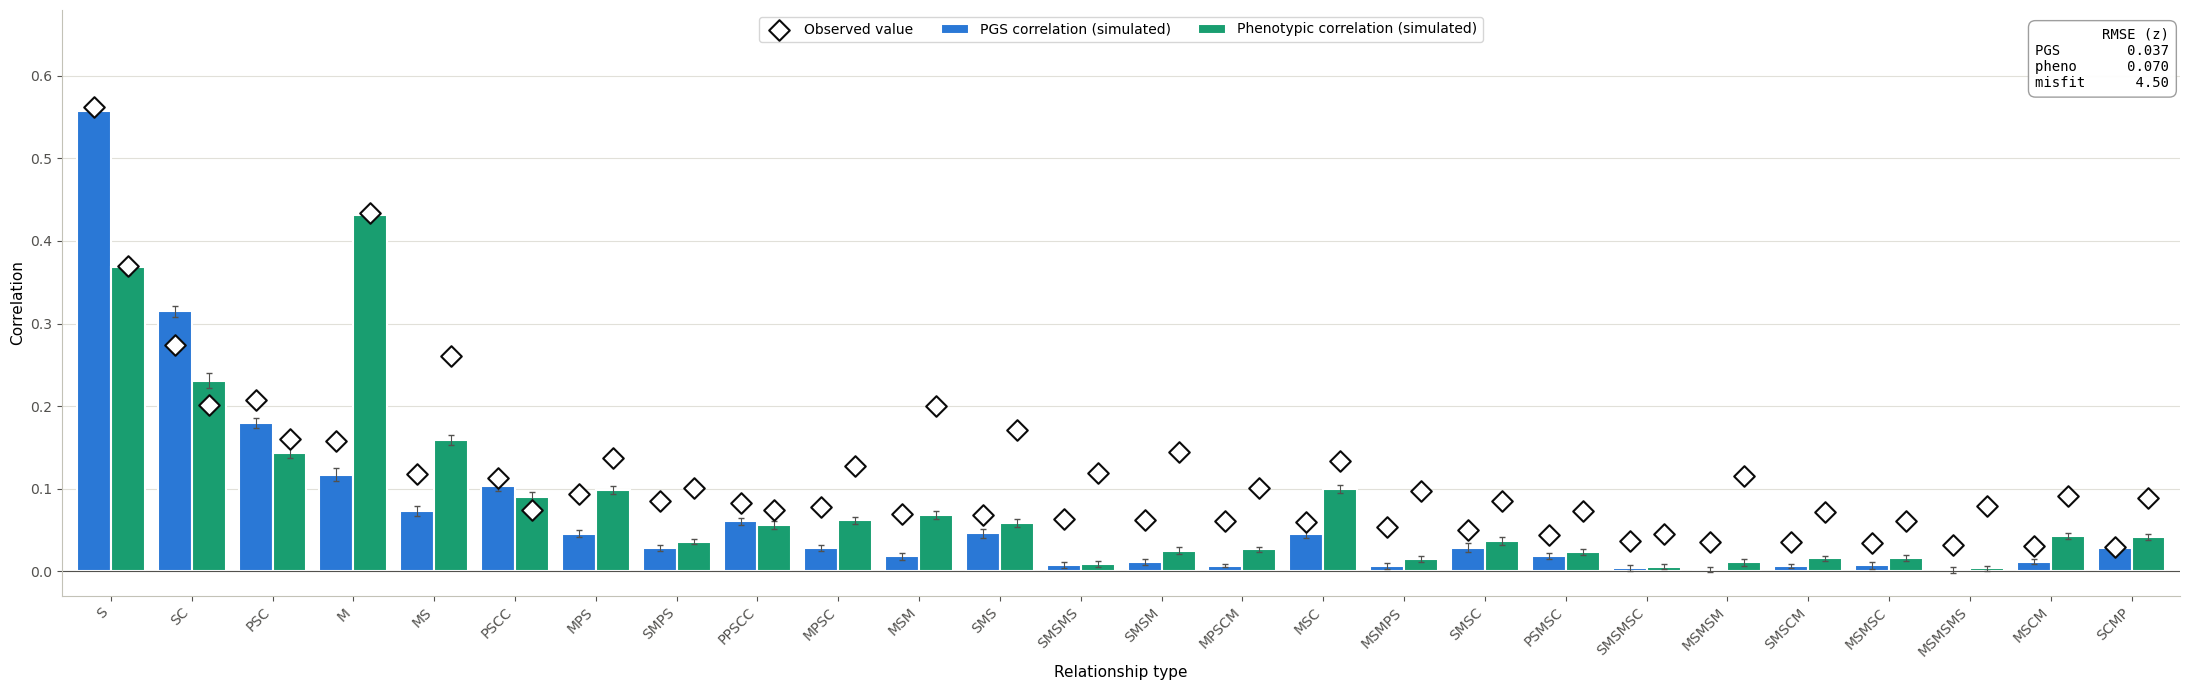


Trait 1 (AE): simulated vs observed


correlations,n,RMSE (z),bias (z)
"PGS, 16 original types",16,0.0346,-0.0318
"PGS, 10 added types",10,0.0405,-0.0270
"PGS, all 26 types",26,0.0370,-0.0300
"phenotypic, 16 original types",16,0.0776,-0.0639
"phenotypic, 10 added types",10,0.0562,-0.0434
"phenotypic, all 26 types",26,0.0702,-0.0560


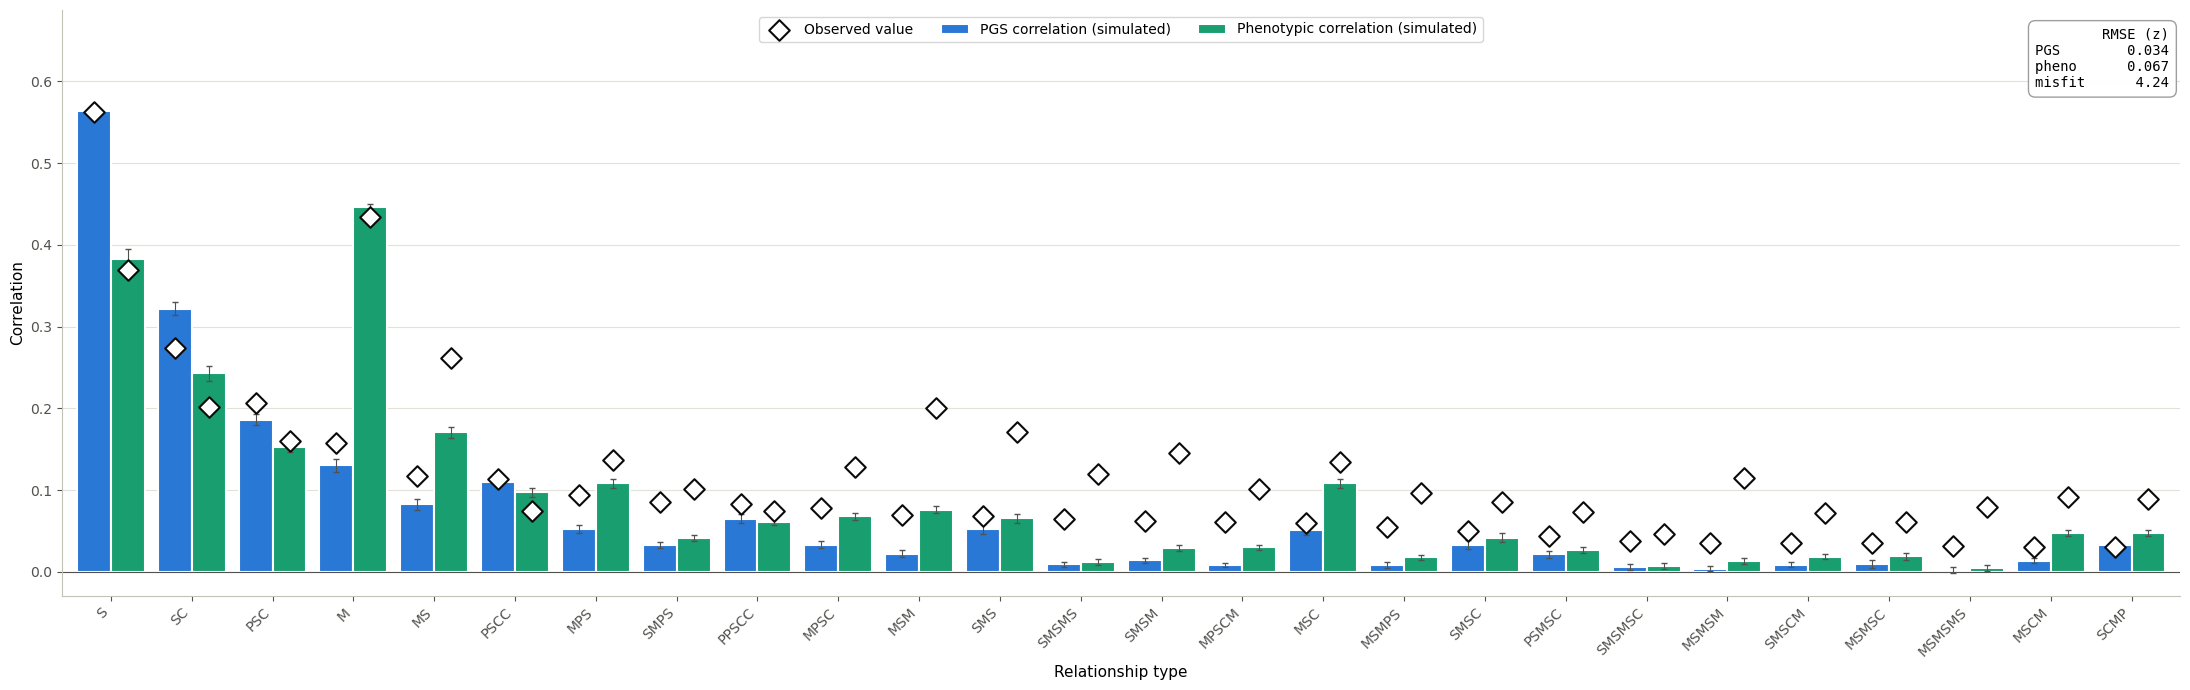


Trait 2 (AFE): simulated vs observed


correlations,n,RMSE (z),bias (z)
"PGS, 16 original types",16,0.0307,-0.0271
"PGS, 10 added types",10,0.0389,-0.0228
"PGS, all 26 types",26,0.0341,-0.0255
"phenotypic, 16 original types",16,0.0737,-0.0572
"phenotypic, 10 added types",10,0.0534,-0.0375
"phenotypic, all 26 types",26,0.0666,-0.0496


In [5]:
plot_condition("01DirAM")

## Condition 02 — AE latent AM (trait 1 = EA)

Trait 1 is EA (AE model: a PGS part and a latent genetic part plus unique environment). Mating is phenotypic
assortative mating on trait 2, a fully latent factor (no PGS) that is genetically (`rg`) and environmentally
(`re`) correlated with EA. No vertical transmission, no shared family environment. NPE fit:
`02AElatentAM_wider`.

| Fixed parameter | Meaning | Value |
|---|---|---|
| `am11`, `am12`, `am21` | assortative mating (spousal correlations) | 0 |
| `f11`, `f22`, `f12`, `f21` | vertical transmission | 0 |
| `prop_h2_latent2` | share of trait-2 genetic variance not captured by a PGS | 1 |
| h²2 | founder heritability of trait 2 (`vg2` = 0.5 in the scripts) | 0.67 |
| `s11`, `s12`, `s21`, `s22` | shared family environment | 0 |
| **Simulation** | | |
| generations | generations simulated (generations analysed) | 15 (analysed 12–14) |
| iterations | simulation replicates | 100 |

**Estimated parameters** (posterior mean; for founder h², the value at the posterior mean of `vg`, which is what
was simulated; *position in range*: 0% = lower, 100% = upper end of the simulated range; *previous*: the `ea4pheno`
run):

In [6]:
parameter_table("02AElatentAM")

02AElatentAM_wider: 7.2% of the unrestricted posterior inside the simulated range -> rejection sampling (4,000 draws)


NPE fit,parameter,meaning,estimate,posterior SD,95% interval,simulated range,position in range,previous estimate,previous range,change
02AElatentAM_wider,prop_h2_latent1,share of trait-1 genetic variance not captured by the PGS,0.6736,0.0390,0.595 – 0.756,0.05 – 0.95,69%,0.7894,0.30 – 0.90,-0.1158
02AElatentAM_wider,h²1 (founder),"founder (base) heritability of trait 1, 1/(2 − vg1)",0.5146,0.0017,0.513 – 0.519,0.51 – 0.95,0%,0.5649,0.56 – 0.83,-0.0503
02AElatentAM_wider,re,environmental correlation between the traits,0.8062,0.0278,0.750 – 0.860,0.00 – 0.95,85%,0.5425,0.00 – 0.60,0.2637
02AElatentAM_wider,am22,spousal correlation on trait 2,0.7259,0.0086,0.709 – 0.743,0.05 – 0.95,75%,0.7449,0.25 – 0.75,-0.0190
02AElatentAM_wider,rg,genetic correlation between the traits,0.6727,0.0206,0.632 – 0.712,0.00 – 0.99,68%,0.8157,0.20 – 0.90,-0.1430


The largest change is in `re`, 0.54 → 0.81, which the previous range capped at 0.60; `rg` falls from 0.82 to
0.67. `am22` (0.73) is no longer at the top of its range. Founder h² is at the lower end of its range (0.51, from 0.56).
Only 7.2% of the unrestricted posterior lies inside the simulated range, and the very small posterior SDs (0.009
for `am22`) should not be taken at face value, since no training simulation reproduces the data.

In the figure, spouses and in-laws are now close, and most correlations are only a little too high (41 of 52). The
misses that stand out are phenotypic correlations among blood relatives: `SC` 0.312 against 0.202, `PSCC` 0.176
against 0.074, `S` 0.434 against 0.369, `PSC` 0.232 against 0.160.

Condition 02 — AE latent AM: results_npe_unweighted_02AElatentAM_wider/predictions/summary_statistics_02AElatentAM_wider.csv (100 replicates)


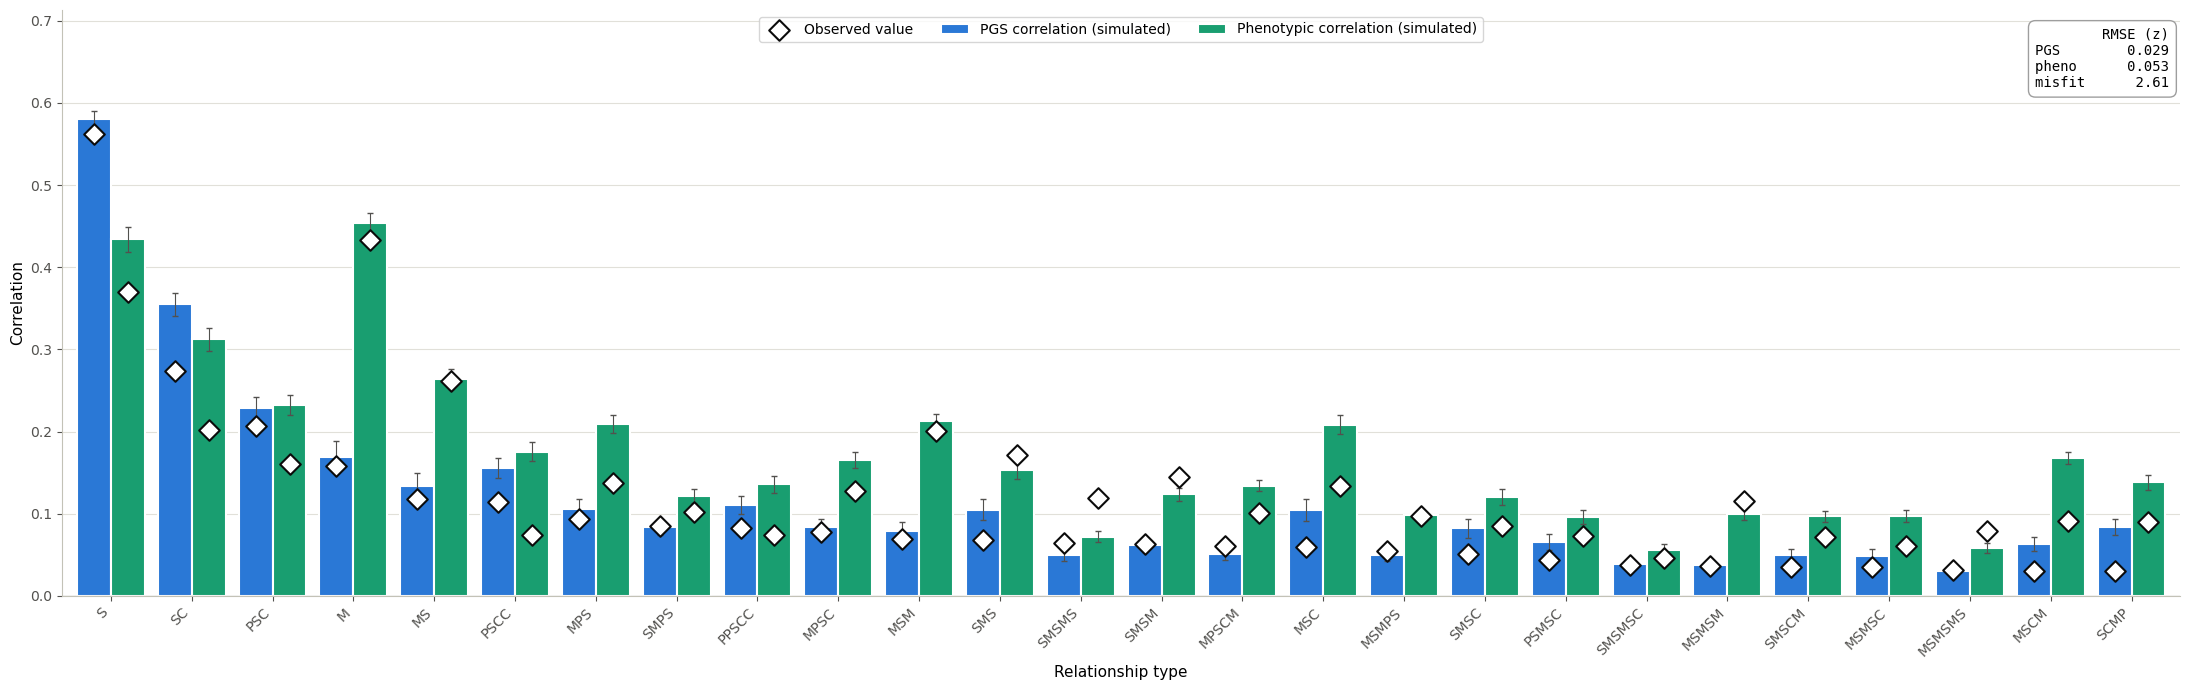


Trait 1 (EA): simulated vs observed


correlations,n,RMSE (z),bias (z)
"PGS, 16 original types",16,0.0223,0.0159
"PGS, 10 added types",10,0.0380,0.0236
"PGS, all 26 types",26,0.0294,0.0188
"phenotypic, 16 original types",16,0.0428,0.0197
"phenotypic, 10 added types",10,0.0652,0.0543
"phenotypic, all 26 types",26,0.0526,0.0330


In [7]:
plot_condition("02AElatentAM")

## Condition 03 — Environmental latent AM (trait 1 = EA)

As condition 02 (mating on the fully latent trait 2, genetically correlated with EA), plus within-trait vertical
transmission on both traits (`f11`, `f22`). The shared family environment `s = 0.5` has no effect in this
engine. The environmental correlation is fixed at `re = 0.1` and `prop_h2_latent1` at 0.7. NPE fit:
`03EnvLatentAM_wider`.

| Fixed parameter | Meaning | Value |
|---|---|---|
| `prop_h2_latent1` | share of trait-1 genetic variance not captured by the PGS | 0.7 |
| `re` | environmental correlation between the traits | 0.1 |
| `am11`, `am12`, `am21` | assortative mating (spousal correlations) | 0 |
| `prop_h2_latent2` | share of trait-2 genetic variance not captured by a PGS | 1 |
| h²2 | founder heritability of trait 2 (`vg2` = 0.5 in the scripts) | 0.67 |
| `s11`, `s12`, `s21`, `s22` | shared family environment (no effect: this engine ignores `s`) | 0.5 |
| `f12`, `f21` | cross-trait vertical transmission | 0 |
| **Simulation** | | |
| generations | generations simulated (generations analysed) | 15 (analysed 12–14) |
| iterations | simulation replicates | 100 |

**Estimated parameters** (posterior mean; for founder h², the value at the posterior mean of `vg`, which is what
was simulated; *position in range*: 0% = lower, 100% = upper end of the simulated range; *previous*: the `ea4pheno`
run):

In [8]:
parameter_table("03EnvLatentAM")

03EnvLatentAM_wider: 0.0% of the unrestricted posterior inside the simulated range -> mcmc sampling (20,000 draws)


NPE fit,parameter,meaning,estimate,posterior SD,95% interval,simulated range,position in range,previous estimate,previous range,change
03EnvLatentAM_wider,h²1 (founder),"founder (base) heritability of trait 1, 1/(2 − vg1)",0.5240,0.0148,0.513 – 0.561,0.51 – 0.95,3%,0.7897,0.63 – 0.83,-0.2656
03EnvLatentAM_wider,f11,"vertical transmission, trait 1",0.0919,0.0197,0.026 – 0.135,0.00 – 0.40,23%,0.1584,0.05 – 0.30,-0.0665
03EnvLatentAM_wider,f22,"vertical transmission, trait 2",0.1122,0.0724,0.003 – 0.272,0.00 – 0.40,28%,0.0575,0.05 – 0.30,0.0547
03EnvLatentAM_wider,am22,spousal correlation on trait 2,0.6941,0.0548,0.624 – 0.865,0.05 – 0.95,72%,0.7303,0.25 – 0.75,-0.0362
03EnvLatentAM_wider,rg,genetic correlation between the traits,0.9169,0.2033,0.027 – 0.990,0.00 – 0.99,93%,0.8982,0.30 – 0.90,0.0187


None of the unrestricted posterior lies inside the simulated range, so these estimates come from MCMC far in the
tail of the flow. Founder h² moves from 0.79 to 0.52, the lower end of its range. The `rg`
posterior has two parts: 95% of the draws are above 0.8 (median 0.974) and 5% are below 0.5, so the mean of 0.917
does not describe either part well.

In the figure, all 52 correlations are too high. Spouses match (0.450 against 0.433), but `am22` = 0.69 with
`rg` = 0.92 reaches that through genetic assortment, which also pushes up every relative: `S` 0.635 against 0.369,
`SC` 0.504 against 0.202, `PSC` 0.405 against 0.160 (phenotypic). The PGS correlations are also too high (bias
0.081).

Condition 03 — Environmental latent AM: results_npe_unweighted_03EnvLatentAM_wider/predictions/summary_statistics_03EnvLatentAM_wider.csv (100 replicates)


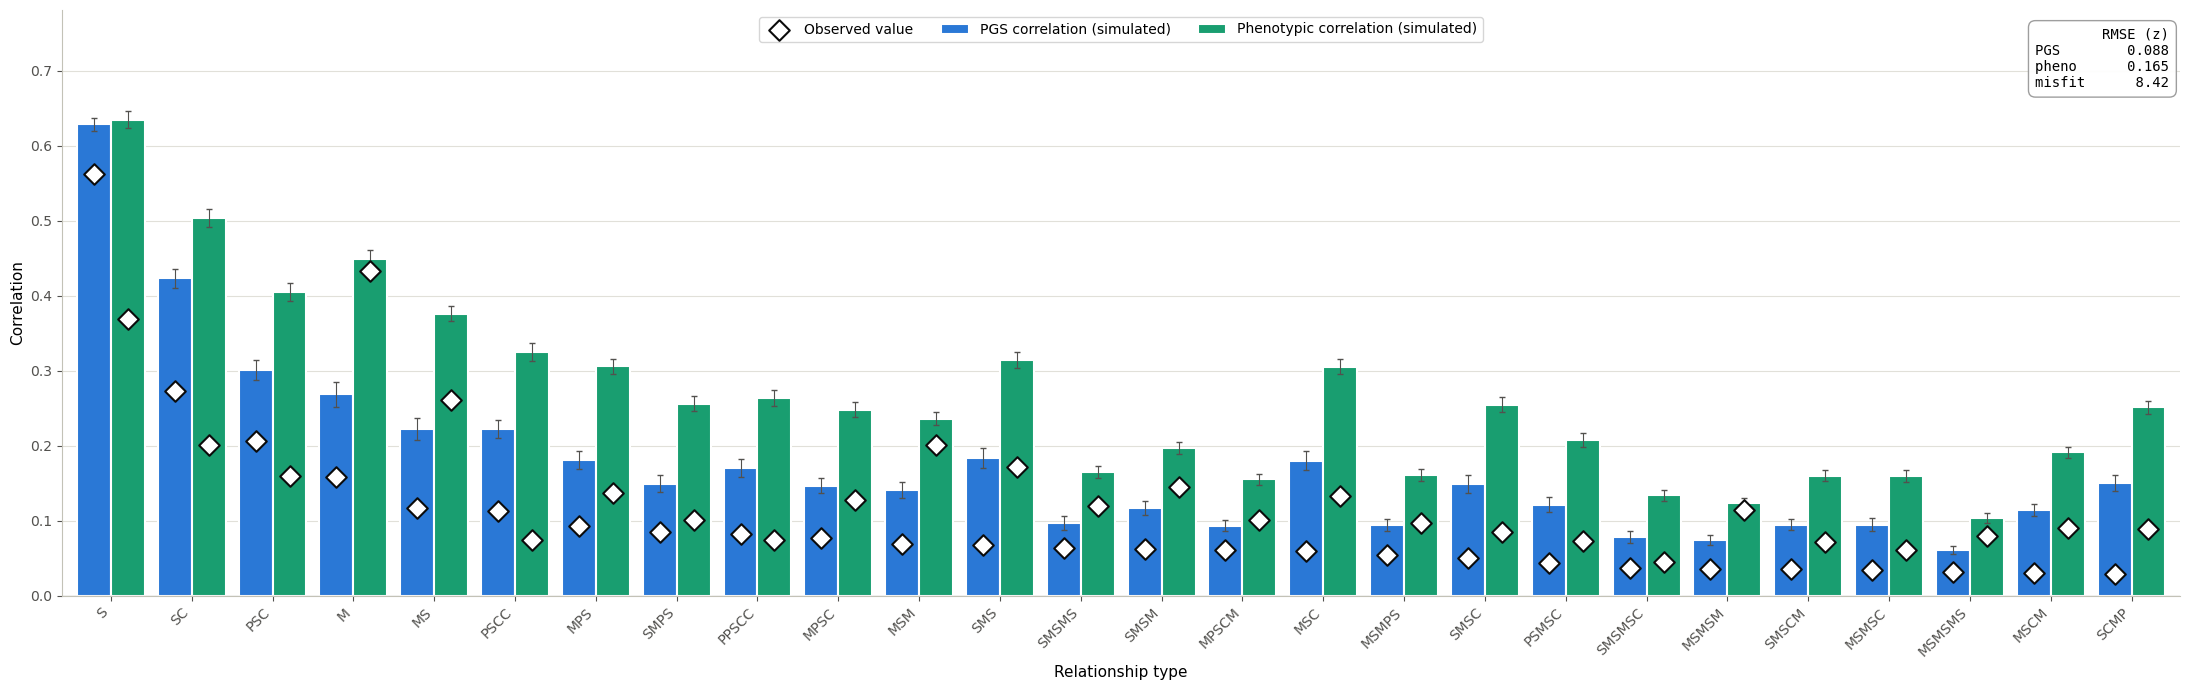


Trait 1 (EA): simulated vs observed


correlations,n,RMSE (z),bias (z)
"PGS, 16 original types",16,0.0852,0.0792
"PGS, 10 added types",10,0.0934,0.0848
"PGS, all 26 types",26,0.0884,0.0813
"phenotypic, 16 original types",16,0.1560,0.1240
"phenotypic, 10 added types",10,0.1785,0.1556
"phenotypic, all 26 types",26,0.1650,0.1362


In [9]:
plot_condition("03EnvLatentAM")

## Condition 04 — EA-driven migration (trait 1 = EA)

EA is additive genetics (a PGS part and a latent part) plus unique environment: no assortative mating (random
mating within islands), no vertical transmission, no shared environment. There are 5 islands; each generation a
fraction `move_p` of each sex on each island migrates, and the movers are sorted on EA, so high-EA movers end up
on the high-numbered islands. The population starts from random founders and runs `n_gen` generations. Trait 2
is an inert dummy required by the bivariate engine. NPE fit: `04EAmigration_wider`.

| Fixed parameter | Meaning | Value |
|---|---|---|
| h²2 | dummy trait 2: founder heritability (`vg2` = 0.5 in the scripts) | 0.67 |
| `prop_h2_latent2` | dummy trait 2: fully latent | 1 |
| `rg`, `re` | genetic and environmental correlation between the traits | 0 |
| `f11`, `f12`, `f21`, `f22` | vertical transmission | 0 |
| `am11`, `am12`, `am21`, `am22` | assortative mating (spousal correlations) | 0 |
| **Simulation** | | |
| generations | generations simulated (generations analysed) | `n_gen` = 4 (analysed 1–3) |
| iterations | simulation replicates | 100 |

**Estimated parameters** (posterior mean; for founder h², the value at the posterior mean of `vg`, which is what
was simulated; *position in range*: 0% = lower, 100% = upper end of the simulated range; *previous*: the `ea4pheno`
run): `n_gen` is the posterior mode.

In [10]:
parameter_table("04EAmigration")

04EAmigration_wider: 100.0% of the unrestricted posterior inside the simulated range -> rejection sampling (4,000 draws)


NPE fit,parameter,meaning,estimate,posterior SD,95% interval,simulated range,position in range,previous estimate,previous range,change
04EAmigration_wider,move_p,fraction of each sex per island migrating each generation,0.4507,0.0067,0.438 – 0.462,0.01 – 0.95,47%,0.4454,0.01 – 0.70,0.0053
04EAmigration_wider,n_gen,generations since the random founders (categorical posterior),4.0000,0.0000,4.000 – 4.000,4.00 – 10.00,0%,4.0000,3.00 – 10.00,0.0000
04EAmigration_wider,h²1 (founder),"founder (base) heritability of trait 1, 1/(2 − vg1)",0.5822,0.0151,0.554 – 0.610,0.51 – 0.95,16%,0.5986,0.56 – 0.83,-0.0164
04EAmigration_wider,prop_h2_latent1,share of trait-1 genetic variance not captured by the PGS,0.6346,0.0299,0.572 – 0.687,0.05 – 0.95,65%,0.7136,0.30 – 0.90,-0.0791


The whole posterior lies inside the simulated range, and the estimates are close to the previous ones (`move_p`
0.445 → 0.451, founder h² 0.60 → 0.58, `prop_h2_latent1` 0.71 → 0.63). `n_gen` = 4 is the lowest value this fit allows,
because `PSCC` and `PPSCC` do not exist at `n_gen` = 3. A check fit without those two types and with `n_gen` 3–10
gives P(`n_gen` = 3) = 0.98, so the estimate depends on that choice.

In the figure, 04 fits best overall (PGS RMSE 0.024, phenotypic 0.044), with most correlations slightly too high
(40 of 52). The largest misses are the phenotypic correlations of three added in-law types: `MSCM` 0.194 against
0.091, `MPSCM` 0.181 against 0.101, `SCMP` 0.157 against 0.089.

Condition 04 — EA-driven migration: results_npe_unweighted_04EAmigration_wider/predictions/summary_statistics_04EAmigration_wider.csv (100 replicates)


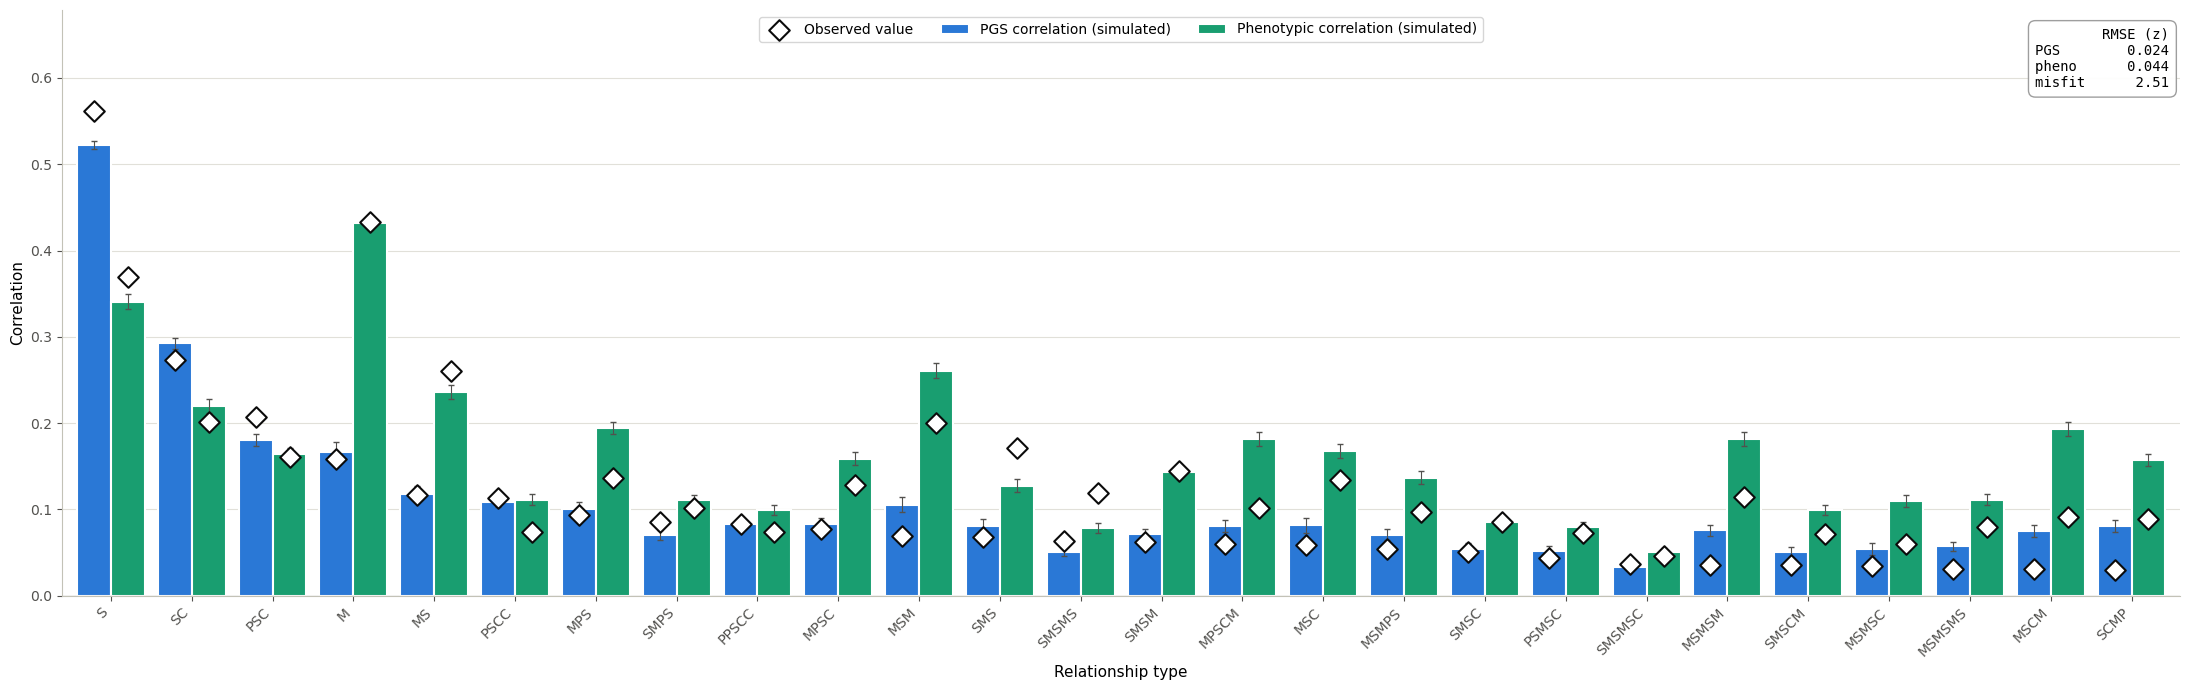


Trait 1 (EA): simulated vs observed


correlations,n,RMSE (z),bias (z)
"PGS, 16 original types",16,0.0238,0.0054
"PGS, 10 added types",10,0.0251,0.0163
"PGS, all 26 types",26,0.0243,0.0096
"phenotypic, 16 original types",16,0.0351,0.0090
"phenotypic, 10 added types",10,0.0559,0.0481
"phenotypic, all 26 types",26,0.0443,0.0241


In [11]:
plot_condition("04EAmigration")

## The fits against their training simulations

The table uses the training data of each wider fit (`nn_training_*_wider.csv` and the row filters of
`run_npe_pipeline.py`) and its 52 features. It compares each condition's observed data with its training
simulations, with the simulation at this run's estimate, and with the best-fitting training simulation. A training
simulation is a single replicate, so the best of 20,000 is slightly favoured by noise; the predicted condition
averages 100 replicates.

In [12]:
# training data of each wider fit, as in run_npe_pipeline.py (RUNS): file and row filter
TRAINING = {"01DirAM_AE": ("01DirAM_wider", None), "01DirAM_AFE": ("01DirAM_wider", None),
            "02AElatentAM": ("02AElatentAM_wider", None), "03EnvLatentAM": ("03EnvLatentAM_wider", None),
            "04EAmigration": ("04EAmigration_wider", "param_n_gen >= 4")}
SUMMARY_OF = {"01DirAM_AE": "01DirAM_AE", "01DirAM_AFE": "01DirAM_AE", "02AElatentAM": "02AElatentAM",
              "03EnvLatentAM": "03EnvLatentAM", "04EAmigration": "04EAmigration"}
_training_files = {}


def features(fit):
    return (script_dir / "run_specs" / f"{fit}_wider" / "features.txt").read_text().split()


def fit_params(fit):
    return (script_dir / "run_specs" / f"{fit}_wider" / "params.txt").read_text().split()


def training_data(fit):
    """Training simulations of a wider fit with all its features present."""
    data, row_filter = TRAINING[fit]
    if data not in _training_files:
        _training_files[data] = pd.read_csv(script_dir / f"nn_training_{data}.csv")
    d = _training_files[data]
    return (d.query(row_filter) if row_filter else d).dropna(subset=features(fit))


def observed(feats):
    """Observed values of NPE features such as S_PGS1 or M_Y2."""
    return pd.Series({f: (obs_pgs if "_PGS" in f else obs_pheno)[f.rsplit("_", 1)[0]] for f in feats})


def observed_se(feats):
    return pd.Series({f: (pgs_table if "_PGS" in f else pheno_table).loc[f.rsplit("_", 1)[0], "SE"] for f in feats})


def simulated(fit, feats):
    """Mean over replicates of the predicted condition at this run's estimate, for an NPE fit's features."""
    s = pd.read_csv(pred_path(SUMMARY_OF[fit]))
    return pd.Series({f"{r.RelationshipPath}_{r.Variable}": r.Correlation_Mean for r in s.itertuples()})[feats]


def rmse_z(values, obs):
    return np.sqrt((z_diff(values, obs) ** 2).mean(axis=-1 if isinstance(values, np.ndarray) else 0))


def misfit_row(values, obs, se):
    return np.sqrt((((values - obs) / np.sqrt(se ** 2 + TOL ** 2)) ** 2).mean(axis=1 if values.ndim == 2 else 0))


rows = []
for fit in TRAINING:
    feats = features(fit)
    d, obs, se = training_data(fit), observed(feats), observed_se(feats)
    X = d[feats]
    rmse = np.sqrt((z_diff(X, obs) ** 2).mean(axis=1))
    est = simulated(fit, feats)
    est_rmse = np.sqrt((z_diff(est, obs) ** 2).mean())
    outside = [f"{f} ({obs[f]:.3f}; simulated {X[f].min():.3f}–{X[f].max():.3f})"
               for f in feats if not X[f].min() <= obs[f] <= X[f].max()]
    rows.append({"NPE fit": f"{fit}_wider", "training simulations": len(d), "features": len(feats),
                 "observed outside the simulated range": "; ".join(outside) or "–",
                 "RMSE (z): best training simulation": rmse.min(),
                 "RMSE (z): at the estimate": est_rmse,
                 "simulations fitting better than the estimate": f"{(rmse < est_rmse).mean():.1%}",
                 "misfit: best training simulation": misfit_row(X, obs, se).min(),
                 "misfit: at the estimate": misfit_row(est, obs, se)})
show(pd.DataFrame(rows), precision=3)

NPE fit,training simulations,features,observed outside the simulated range,RMSE (z): best training simulation,RMSE (z): at the estimate,simulations fitting better than the estimate,misfit: best training simulation,misfit: at the estimate
01DirAM_AE_wider,20000,52,–,0.045,0.056,6.1%,3.348,4.500
01DirAM_AFE_wider,20000,52,–,0.047,0.053,0.3%,3.368,4.235
02AElatentAM_wider,20000,52,–,0.032,0.043,0.7%,2.291,2.609
03EnvLatentAM_wider,20000,52,–,0.049,0.132,68.5%,3.602,8.417
04EAmigration_wider,17500,52,–,0.031,0.036,0.2%,2.291,2.514


- **Each observed correlation now lies inside its simulated range.** In the previous run, condition 03's sibling
  phenotypic correlation did not.
- **In 01, 02 and 04 the estimate is near the best the training data offer:** 6.1%, 0.3%, 0.7% and 0.2% of the
  simulations fit better than it does (RMSE z, in the order of the table).
- **In 03 the estimate is poor:** 68.5% of the training simulations fit better, with a misfit of 8.42 at the estimate
  against 3.60 for the best training simulation.
- **Even the best training simulation of each fit has a misfit of at least 2.29,** so on this engine no setting in the
  simulated ranges agrees with the observed correlations within sampling error.

### The spousal–sibling trade-off

Every training simulation of conditions 02 and 03 by its spousal (`M_Y1`) and sibling (`S_Y1`) phenotypic EA
correlation, with the observed values, the simulation at this run's estimate and the best-fitting training simulation.

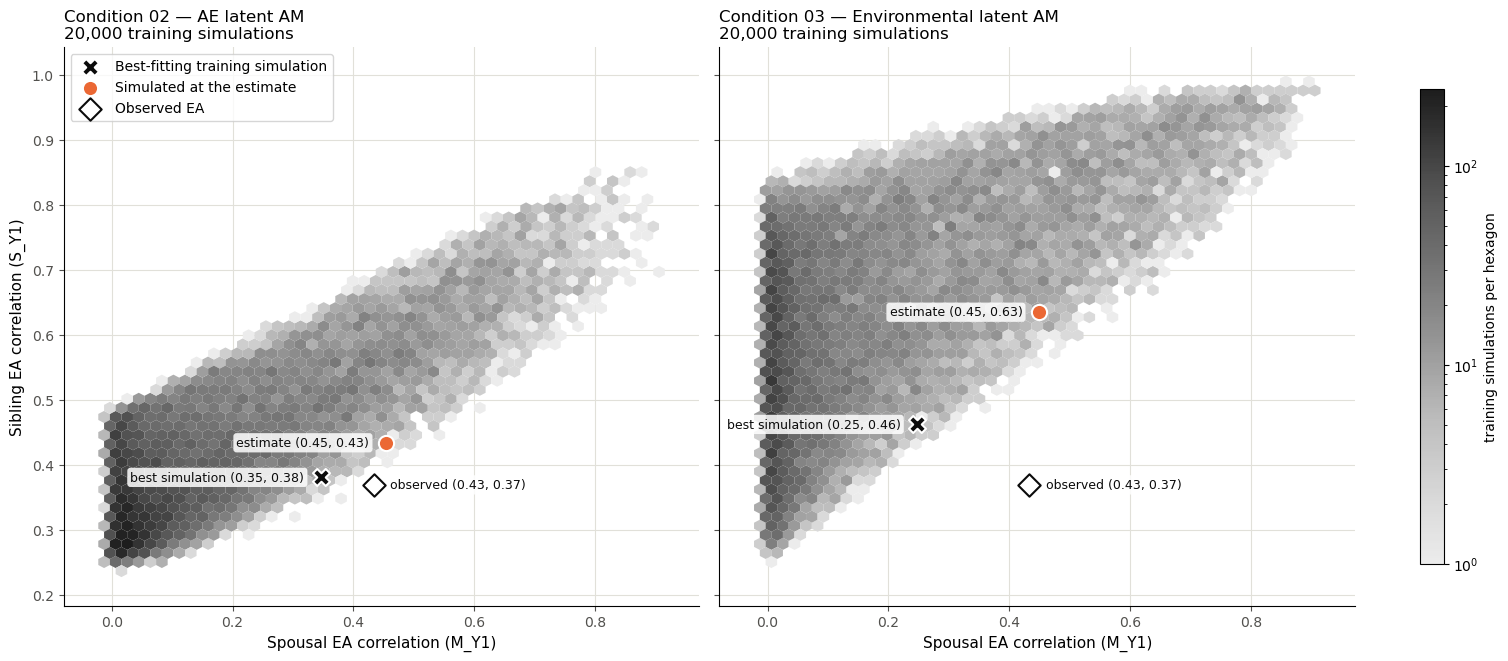

02AElatentAM_wider: 3,000 of 20,000 simulations have M_Y1 >= 0.40; their S_Y1 is 0.394 or more (median 0.616). Lowest S_Y1 of all simulations: 0.243 (observed 0.369).
03EnvLatentAM_wider: 3,384 of 20,000 simulations have M_Y1 >= 0.40; their S_Y1 is 0.522 or more (median 0.835). Lowest S_Y1 of all simulations: 0.253 (observed 0.369).


In [13]:
# grey ramp from light grey (one simulation) to near-black, so sparse hexagons stay visible
DENSITY = LinearSegmentedColormap.from_list("density", plt.cm.Greys(np.linspace(0.15, 0.9, 256)))
SHORT_LABEL = {"Best-fitting training simulation": "best simulation", "Simulated at the estimate": "estimate",
               "Observed EA": "observed"}
TITLES = {"02AElatentAM": CONDITIONS["02AElatentAM"]["title"], "03EnvLatentAM": CONDITIONS["03EnvLatentAM"]["title"]}
clouds = pd.concat([training_data(fit)[["M_Y1", "S_Y1"]] for fit in TITLES])
extent = (clouds["M_Y1"].min() - 0.02, clouds["M_Y1"].max() + 0.02, clouds["S_Y1"].min() - 0.02, clouds["S_Y1"].max() + 0.02)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), sharex=True, sharey=True, layout="constrained")
hexbins = []
for ax, fit in zip(axes, TITLES):
    feats = features(fit)
    d, obs = training_data(fit), observed(feats)
    best = d.loc[(z_diff(d[feats], obs) ** 2).mean(axis=1).idxmin()]
    est = simulated(fit, feats)
    hexbins.append(ax.hexbin(d["M_Y1"], d["S_Y1"], gridsize=50, cmap=DENSITY, mincnt=1, linewidths=0, extent=extent))
    points = (("Best-fitting training simulation", best, dict(marker="X", s=150, color=INK), "right"),
              ("Simulated at the estimate", est, dict(marker="o", s=120, color=ACCENT), "right"),
              ("Observed EA", obs, dict(marker="D", s=130, facecolor="white", edgecolor=INK), "left"))
    for label, p, style, align in points:     # labels left of the point, except the observed one
        style = {"edgecolor": "white", **style}
        ax.scatter(p["M_Y1"], p["S_Y1"], linewidth=1.5, zorder=5, label=label, **style)
        ax.annotate(f"{SHORT_LABEL[label]} ({p['M_Y1']:.2f}, {p['S_Y1']:.2f})", (p["M_Y1"], p["S_Y1"]),
                    xytext=(-12 if align == "right" else 12, 0), textcoords="offset points", ha=align, va="center",
                    fontsize=9, color=INK,
                    bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="none", alpha=0.85))
    ax.set_title(f"{TITLES[fit]}\n{len(d):,} training simulations", loc="left", fontsize=12)
    ax.set_xlabel("Spousal EA correlation (M_Y1)", fontsize=11)
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=MUTED)
axes[0].set_ylabel("Sibling EA correlation (S_Y1)", fontsize=11)
axes[0].legend(loc="upper left", fontsize=10, frameon=True)
norm = LogNorm(vmin=1, vmax=max(h.get_array().max() for h in hexbins))
for h in hexbins:
    h.set_norm(norm)
fig.colorbar(hexbins[-1], ax=axes, label="training simulations per hexagon", shrink=0.85)
plt.show()

for fit in TITLES:
    d = training_data(fit)
    high = d[d["M_Y1"] >= 0.40]
    print(f"{fit}_wider: {len(high):,} of {len(d):,} simulations have M_Y1 >= 0.40; their S_Y1 is "
          f"{high['S_Y1'].min():.3f} or more (median {high['S_Y1'].median():.3f}). "
          f"Lowest S_Y1 of all simulations: {d['S_Y1'].min():.3f} (observed {obs_pheno['S']:.3f}).")

The observed point (spouses 0.43, siblings 0.37) lies just below the condition 02 cloud and well below the condition 03
cloud. Every simulation with a spousal correlation of 0.40 or more has a sibling correlation of at least 0.39 in 02 and
0.52 in 03. The best simulations stay short on spouses (0.35 and 0.25); the estimates reach the spouse correlation
and pay for it in siblings (0.43 and 0.63).

`run_rc_paper_wider/diagnose_02_03/diagnose_02_03.ipynb` traces this to two causes: the engine's heritability floor
in every condition, and `re` fixed at 0.1 in condition 03.

### This run's estimate against the best training simulations

In [14]:
shown = ["S_Y1", "PSC_Y1", "M_Y1", "MS_Y1", "S_PGS1", "M_PGS1"]


def best_simulations(fit):
    """This run's estimate against the five training simulations closest to the observed correlations."""
    feats, params = features(fit), fit_params(fit)
    d, obs = training_data(fit), observed(feats)
    pgs_f, ph_f = [f for f in feats if "_PGS" in f], [f for f in feats if "_Y" in f]

    def fit_summary(values):
        z2 = z_diff(values[feats].astype(float), obs) ** 2
        return {"RMSE (z)": np.sqrt(z2.mean()), "PGS RMSE (z)": np.sqrt(z2[pgs_f].mean()),
                "pheno RMSE (z)": np.sqrt(z2[ph_f].mean()), **values[shown].astype(float)}

    def parameter_columns(value_of):
        """Parameter values of one table row, with founder h² in place of vg."""
        return {H2_LABEL.get(p, p): founder_h2(value_of(p)) if p in H2_LABEL else value_of(p) for p in params}

    estimate = pd.read_csv(predictions_dir(fit) / "posterior_summary.csv").set_index("parameter")["mean"]
    rmse = np.sqrt((z_diff(d[feats], obs) ** 2).mean(axis=1))
    rows = [{"": "observed", **obs[shown]},
            {"": "simulated at the estimate (100 replicates)", **parameter_columns(lambda p: estimate[p]),
             **fit_summary(simulated(fit, feats))}]
    for i in rmse.nsmallest(5).index:
        rows.append({"": f"training simulation {d.loc[i, 'Condition']}",
                     **parameter_columns(lambda p: d.loc[i, f"param_{p}"]), **fit_summary(d.loc[i])})
    print(f"{fit}_wider")
    columns = ["", *[H2_LABEL.get(p, p) for p in params], "RMSE (z)", "PGS RMSE (z)", "pheno RMSE (z)", *shown]
    show(pd.DataFrame(rows)[columns], precision=3)


best_simulations("02AElatentAM")
best_simulations("03EnvLatentAM")

02AElatentAM_wider


,prop_h2_latent1,h²1 (founder),re,am22,rg,RMSE (z),PGS RMSE (z),pheno RMSE (z),S_Y1,PSC_Y1,M_Y1,MS_Y1,S_PGS1,M_PGS1
observed,–,–,–,–,–,–,–,–,0.369,0.160,0.433,0.261,0.562,0.158
simulated at the estimate (100 replicates),0.674,0.515,0.806,0.726,0.673,0.043,0.029,0.053,0.434,0.232,0.454,0.264,0.580,0.170
training simulation Condition_02556,0.427,0.559,0.878,0.736,0.477,0.032,0.021,0.040,0.381,0.169,0.346,0.187,0.570,0.142
training simulation Condition_17474,0.540,0.563,0.917,0.688,0.590,0.033,0.021,0.041,0.388,0.171,0.383,0.195,0.564,0.133
training simulation Condition_11589,0.563,0.527,0.878,0.757,0.438,0.033,0.019,0.043,0.351,0.157,0.331,0.177,0.556,0.128
training simulation Condition_04841,0.763,0.551,0.933,0.713,0.468,0.034,0.026,0.040,0.379,0.175,0.363,0.192,0.539,0.103
training simulation Condition_07979,0.838,0.515,0.658,0.742,0.562,0.034,0.026,0.041,0.403,0.206,0.372,0.229,0.548,0.093


03EnvLatentAM_wider


,h²1 (founder),f11,f22,am22,rg,RMSE (z),PGS RMSE (z),pheno RMSE (z),S_Y1,PSC_Y1,M_Y1,MS_Y1,S_PGS1,M_PGS1
observed,–,–,–,–,–,–,–,–,0.369,0.160,0.433,0.261,0.562,0.158
simulated at the estimate (100 replicates),0.524,0.092,0.112,0.694,0.917,0.132,0.088,0.165,0.635,0.405,0.450,0.376,0.629,0.269
training simulation Condition_08920,0.608,0.012,0.071,0.699,0.585,0.049,0.020,0.066,0.462,0.233,0.248,0.198,0.556,0.123
training simulation Condition_15180,0.564,0.005,0.136,0.625,0.685,0.050,0.021,0.068,0.435,0.225,0.232,0.187,0.568,0.132
training simulation Condition_06768,0.521,0.015,0.038,0.569,0.855,0.050,0.022,0.067,0.451,0.225,0.271,0.195,0.566,0.134
training simulation Condition_17274,0.532,0.037,0.094,0.752,0.481,0.050,0.020,0.068,0.416,0.210,0.205,0.165,0.557,0.124
training simulation Condition_11746,0.542,0.011,0.088,0.596,0.827,0.050,0.022,0.068,0.457,0.241,0.276,0.209,0.567,0.137


- **Condition 02.** The five best simulations have `re` 0.66–0.93 and `am22` 0.69–0.76, like the estimate, but lower
  `rg` (0.44–0.59 against 0.67). They fit siblings better (0.35–0.40) and spouses worse (0.33–0.38).
- **Condition 03.** The estimate has much higher `f11` (0.092 against 0.005–0.037) and `rg` (0.92 against 0.48–0.86)
  than the five best simulations, whose PGS RMSE is 0.020–0.022 against 0.088 at the estimate. Those simulations still miss
  the phenotypic correlations (siblings 0.42–0.46, spouses 0.21–0.28), so that part of the misfit belongs to the model.

## What this run means for the next one

- **The founder heritabilities here are limited by the old engine.** In 01, 02 and 03 they sit at its floor of 0.51, above
  the 0.3–0.4 wanted for EA, so the fits could not go lower.
- **Use the corrected engine next.** `Scripts/run_rc_paper_rescaled/` re-runs all four conditions with `vg` as founder
  heritability and `s_mat` applied. Condition 03 there fixes `re` and `prop_h2_latent1` at 0.7 and `s` at 0.3.
- **What to expect for condition 03.** Replicated local simulations of that design at a founder h² of 0.35 gave a misfit of 1.51,
  against 8.42 here. Those runs used hand-chosen parameters and a smaller population (N = 12,000), so they show the
  direction, not a result. The NPE has not been fitted on corrected-scale data yet.
- **The predicted-condition scripts still hold the `_wider` estimates.** They need the `_rescaled` estimates before
  they are submitted on the corrected engine.